# In-context inference vs number of operations (k = 1, 3) — 3 demonstrations, neutral prompt

The prompt is the same as in notebook 48: **it says nothing about the operations**, only that the same hidden
transformation is applied in every example. There are two experiments, as before: `answer` (give the grid) and
`describe` (describe the rule in words first, then give the grid).

**Hidden transformations.** For each k, ALL transformations that need **exactly k operations**, i.e. group elements
whose shortest A/B/C word has length k. A word like CCA equals A, so it counts as k = 1, never as 3.
* k = 1: A, B, C (3 transformations)
* k = 3: 18 transformations (AAA, AAB, AAC, ABA, ABB, ABC, ACB, BAA, BAB, BAC, BBA, BBB, BBC, BCA, CAA, CAB, CAC, CBA)

**20 tasks per transformation**, the same as for k = 2 in notebook 48 (one replicate): 60 tasks for k = 1 and 360
for k = 3. Each task has 3 demonstrations, checked to determine the transformation uniquely. 420 tasks × 2
experiments = **840 calls** (~$0.5–1).

The report adds the 3-demo k = 2 results from notebook 48, if that folder is present on Drive.

Cell 4 = dry run (no cost). Cell 5 = 4-call pilot. Cell 6 = full run (resumable). Cell 7 = tables, plot and zip.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 137061a3d1ce45f2b7c60a7be0c73a9a1982a694


In [2]:
# --- 3. Configuration ---------------------------------------------------------------------------------------------
MODEL = "openai/gpt-6-luna"
KS = [1, 3]
N_PER_TRANSFORM = 20             # tasks per transformation (k = 2 in notebook 48 also has 20 per transformation)
N_DEMOS = 3
TASK_SEED = 0
HINT = False                     # never tell the model which operations exist
EXPERIMENTS = ["answer", "describe"]
REASONING = None
MAX_TOKENS = None
WORKERS = 128
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
if IN_COLAB and not os.environ.get("OPENROUTER_API_KEY"):
    from google.colab import userdata
    os.environ["OPENROUTER_API_KEY"] = userdata.get("OPENROUTER_API_KEY")      # never printed
print("OpenRouter key present:", bool(os.environ.get("OPENROUTER_API_KEY")))
import json, pathlib
import numpy as np
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 300); pd.set_option("display.width", 220)
from decompositionality import icl_api as IA
_tag = "default" if not REASONING else "_".join(f"{k}{v}" for k, v in REASONING.items())
OUT_DIR = pathlib.Path(RESULTS_ROOT) / "icl_api" / f"klen13_nohint_{MODEL.replace('/', '_')}_demos{N_DEMOS}_n{N_PER_TRANSFORM}_seed{TASK_SEED}_{_tag}"
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_JSONL = OUT_DIR / "responses.jsonl"
print("results ->", OUT_DIR)


Mounted at /content/drive
OpenRouter key present: True
results -> /content/drive/MyDrive/decompositionality_results/icl_api/klen13_nohint_openai_gpt-6-luna_demos3_n20_seed0_default


In [3]:
# --- 4. Dry run: build the tasks and show a prompt (no API calls) ---------------------------------------------------
tasks = IA.make_tasks_by_length(KS, n_demos=N_DEMOS, seed=TASK_SEED, n_per_transform=N_PER_TRANSFORM)
(OUT_DIR / "tasks.json").write_text(json.dumps(tasks))
for k in KS:
    tk = [t for t in tasks if t["k"] == k]
    print(f"k = {k}: {len(tk)} tasks, {len({t['word'] for t in tk})} distinct transformations")
print("\nExample prompt (k = 3, experiment 'describe'):\n")
print(IA.build_prompt([t for t in tasks if t["k"] == 3][0], "describe", HINT))
print("\ncalls planned:", len(tasks) * len(EXPERIMENTS))


k = 1: 60 tasks, 3 distinct transformations
k = 3: 360 tasks, 18 distinct transformations

Example prompt (k = 3, experiment 'describe'):

Each example below shows a 6x6 grid of digits (Input) and the grid obtained by applying the same hidden transformation to it (Output). The transformation is the same for every example.

Example 1
Input:
9 2 3 1 1 1
9 5 5 8 0 1
5 2 4 5 7 8
4 9 5 5 8 0
3 2 4 8 0 0
6 2 3 3 0 6
Output:
6 9 9 5 4 3
2 2 5 2 9 2
3 3 5 4 5 4
3 1 8 5 5 8
0 1 0 7 8 0
6 1 1 8 0 0

Example 2
Input:
1 2 2 3 1 6
8 3 8 8 3 5
5 9 7 9 8 5
8 2 4 1 4 7
1 0 7 5 1 7
3 4 3 0 7 8
Output:
3 1 8 5 8 1
4 2 3 9 2 0
3 2 8 7 4 7
0 3 8 9 1 5
7 1 3 8 4 1
8 6 5 5 7 7

Example 3
Input:
1 2 5 4 1 8
7 7 7 3 5 7
3 7 4 1 7 1
9 1 4 3 0 1
5 0 7 3 7 7
4 3 2 8 5 4
Output:
4 1 7 3 9 5
3 2 7 7 1 0
2 5 7 4 4 7
8 4 3 1 3 3
5 1 5 7 0 7
4 8 7 1 1 7

Apply the same transformation to this grid:
6 7 7 3 6 2
6 2 4 9 6 3
3 1 4 8 5 7
2 6 2 1 1 4
3 9 1 4 5 2
5 6 2 4 1 2

First, describe the transformation in words, bet

In [4]:
# --- 5. Pilot: 4 calls (k = 5, both experiments) --------------------------------------------------------------------
pilot_tasks = [t for t in tasks if t["k"] == max(KS)][:2]
IA.run(pilot_tasks, OUT_JSONL, MODEL, experiments=EXPERIMENTS, hint=HINT, reasoning=REASONING,
       max_tokens=MAX_TOKENS, workers=WORKERS)
display(IA.score(tasks, OUT_JSONL))


0 calls already done; 4 to run (model openai/gpt-6-luna)
  4/4 calls finished (4 ok)


,task_id,word,k,experiment,parsed,correct,applied,error_type,rule,rule_keywords,prompt_tokens,completion_tokens,reasoning_tokens,cost_usd
0,k3-000,BCA,3,describe,True,True,BCA,correct,"Transpose the grid, then move the last digit o...",transpose,632,1161,1056,0.000644
1,k3-000,BCA,3,answer,True,True,BCA,correct,NaN,NaN,615,1395,1311,0.000759
2,k3-001,BAC,3,answer,True,True,BAC,correct,NaN,NaN,615,1516,1432,0.000820
3,k3-001,BAC,3,describe,True,True,BAC,correct,"Transpose the grid, then shift the rows of the...",transpose > shift > transpose > shift,632,2704,2557,0.001415


In [5]:
# --- 6. Full run (resumable: calls already saved are skipped) --------------------------------------------------------
IA.run(tasks, OUT_JSONL, MODEL, experiments=EXPERIMENTS, hint=HINT, reasoning=REASONING, max_tokens=MAX_TOKENS,
       workers=WORKERS)


4 calls already done; 836 to run (model openai/gpt-6-luna)
  10/836 calls finished (10 ok)
  20/836 calls finished (20 ok)
  30/836 calls finished (30 ok)
  40/836 calls finished (40 ok)
  50/836 calls finished (50 ok)
  60/836 calls finished (60 ok)
  70/836 calls finished (70 ok)
  80/836 calls finished (80 ok)
  90/836 calls finished (90 ok)
  100/836 calls finished (100 ok)
  110/836 calls finished (110 ok)
  120/836 calls finished (120 ok)
  130/836 calls finished (130 ok)
  140/836 calls finished (140 ok)
  150/836 calls finished (150 ok)
  160/836 calls finished (160 ok)
  170/836 calls finished (170 ok)
  180/836 calls finished (180 ok)
  190/836 calls finished (190 ok)
  200/836 calls finished (200 ok)
  210/836 calls finished (210 ok)
  220/836 calls finished (220 ok)
  230/836 calls finished (230 ok)
  240/836 calls finished (240 ok)
  250/836 calls finished (250 ok)
  260/836 calls finished (260 ok)
  270/836 calls finished (270 ok)
  280/836 calls finished (280 ok)
  290/8

836

added 240 k = 2 calls from notebook 48
Accuracy by number of operations k:


mean           count         
experiment answer describe answer describe
k                                         
1           0.967    0.950     60       60
2           0.892    0.825    120      120
3           0.897    0.886    360      360


Error types (share of answers):


error_type    correct  execution slip  other wrong grid  unparsed  wrong transform
experiment k                                                                      
answer     1    0.967           0.017             0.000     0.000            0.017
           2    0.892           0.033             0.042     0.017            0.017
           3    0.897           0.033             0.011     0.025            0.033
describe   1    0.950           0.050             0.000     0.000            0.000
           2    0.825           0.067             0.017     0.008            0.083
           3    0.886           0.022             0.028     0.022            0.042


Accuracy by transformation (k = 1, 2, 3):


experiment  answer  describe
k word                      
1 A           1.00      1.00
  B           0.95      0.85
  C           0.95      1.00
2 AB          0.85      0.70
  AC          1.00      1.00
  BA          0.95      0.90
  BC          1.00      1.00
  CA          0.95      0.70
  CB          0.60      0.65
3 AAA         0.90      1.00
  AAB         0.75      0.85
  AAC         1.00      1.00
  ABA         0.90      0.75
  ABB         0.90      1.00
  ABC         0.85      0.85
  ACB         0.65      0.75
  BAA         0.95      0.95
  BAB         0.95      0.95
  BAC         1.00      0.95
  BBA         0.85      0.90
  BBB         0.80      0.75
  BBC         1.00      1.00
  BCA         0.95      0.95
  CAA         1.00      1.00
  CAB         0.80      0.55
  CAC         1.00      1.00
  CBA         0.90      0.75


Wrong legal transforms (true shortest word -> applied):


,k,word,applied,count
20,3,BBB,BC,6
5,2,BA,BC,3
22,3,CAB,B,3
1,2,AB,B,2
12,3,ABC,BBB,2
13,3,ABC,BC,2
4,2,AB,I,2
6,2,CA,C,2
18,3,BAB,BB,2
17,3,ACB,I,2



A few stated rules per k:

k = 1 (accuracy 0.95):
  [A, correct] Shift each row one position to the right, wrapping the last digit around to the beginning.
  [A, correct] Move the last digit of each row to the beginning, shifting the other digits one place to the right.
  [C, correct] Reverse the order of the digits in each row.
  [A, correct] Shift each row one position to the right, wrapping the last digit around to the first position.
  [C, correct] Reverse the order of the digits in each row, reflecting the grid left to right.

k = 2 (accuracy 0.82):
  [AC, correct] Reverse the order of the first five digits in each row, leaving the sixth digit unchanged.
  [AC, correct] Reverse the first five digits in each row, leaving the sixth digit unchanged.
  [AC, correct] Reverse the first five digits in each row, leaving the sixth digit unchanged.
  [AC, correct] Reverse the order of the first five digits in each row, leaving the sixth digit unchanged.
  [AC, correct] In each row, reverse

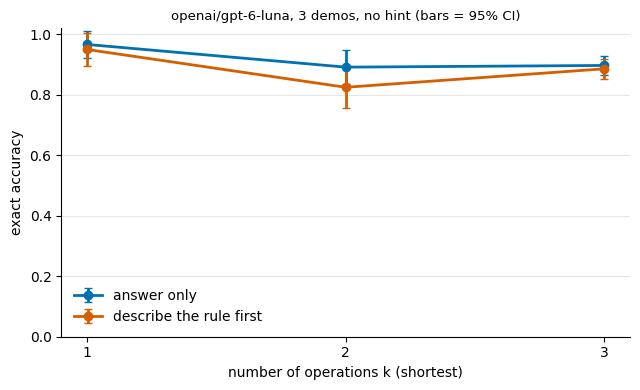


Usage:


,prompt_tokens,completion_tokens,reasoning_tokens,cost_usd
total,673380.0,2373228.0,2266618.0,1.253952


saved to /content/drive/MyDrive/decompositionality_results/icl_api/klen13_nohint_openai_gpt-6-luna_demos3_n20_seed0_default


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
# --- 7. Tables and plot --------------------------------------------------------------------------------------------------
df = IA.score(tasks, OUT_JSONL)
# k = 2 (3 demos) from notebook 48, if available
k2_dir = pathlib.Path(RESULTS_ROOT) / "icl_api" / f"k2_demo_sweep_nohint_{MODEL.replace('/', '_')}_{_tag}"
if (k2_dir / "tasks.json").exists():
    T48 = {int(r): t for r, t in json.loads((k2_dir / "tasks.json").read_text()).items()}
    k2 = IA.score_sweep(T48, k2_dir, [N_DEMOS], sorted(T48))
    if len(k2):
        df = pd.concat([df, k2.drop(columns=["replicate", "n_demos"]).assign(k=2)], ignore_index=True)
        print(f"added {len(k2)} k = 2 calls from notebook 48")
acc = df.pivot_table(index="k", columns="experiment", values="correct", aggfunc=["mean", "count"]).round(3)
print("Accuracy by number of operations k:"); display(acc)
print("\nError types (share of answers):")
display(df.groupby(["experiment", "k"]).error_type.value_counts(normalize=True).unstack(fill_value=0).round(3))
print("\nAccuracy by transformation (k = 1, 2, 3):")
display(df.pivot_table(index=["k", "word"], columns="experiment", values="correct", aggfunc="mean").round(2))
print("\nWrong legal transforms (true shortest word -> applied):")
w = df[df.error_type == "wrong transform"]
display(w.groupby(["k", "word", "applied"]).size().rename("count").reset_index().sort_values("count", ascending=False).head(25))
d = df[df.experiment == "describe"]
print("\nA few stated rules per k:")
for k_, g_ in d.groupby("k"):
    print(f"\nk = {k_} (accuracy {g_.correct.mean():.2f}):")
    for _, r_ in g_.head(5).iterrows():
        print(f"  [{r_.word}, {'correct' if r_.correct else 'wrong'}] {str(r_.rule)[:200]}")
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 4))
for e, c in (("answer", "#0072B2"), ("describe", "#D55E00")):
    q = df[df.experiment == e].groupby("k").correct.agg(["mean", "count"])
    se = np.sqrt(q["mean"] * (1 - q["mean"]) / q["count"])
    ax.errorbar(q.index, q["mean"], yerr=1.96 * se, marker="o", lw=2, capsize=3, color=c,
                label={"answer": "answer only", "describe": "describe the rule first"}[e])
ax.set(xlabel="number of operations k (shortest)", ylabel="exact accuracy", ylim=(0, 1.02), xticks=sorted(df.k.unique()))
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e6e6")
ax.legend(frameon=False); ax.set_title(f"{MODEL}, {N_DEMOS} demos, no hint (bars = 95% CI)", fontsize=9.5)
fig.tight_layout(); fig.savefig(OUT_DIR / "acc_vs_k.png", dpi=150); plt.show()
print("\nUsage:"); display(df[["prompt_tokens", "completion_tokens", "reasoning_tokens", "cost_usd"]]
                           .apply(pd.to_numeric, errors="coerce").sum().to_frame("total").T)
df.to_csv(OUT_DIR / "scores.csv", index=False)
print("saved to", OUT_DIR)
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive(str(OUT_DIR), "zip", OUT_DIR)
    files.download(str(OUT_DIR) + ".zip")
